In [5]:
import os
import joblib
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix

# 1. Aplicar SMOTE sobre el conjunto de entrenamiento
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Distribución original en train: {pd.Series(y_train).value_counts().to_dict()}")
print(f"Distribución tras SMOTE en train: {pd.Series(y_train_res).value_counts().to_dict()}\n")

# 2. Entrenar Random Forest Optimizado con datos balanceados
rf_balanced = RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=42)
rf_balanced.fit(X_train_res, y_train_res)

# 3. Predicciones ajustando el umbral de decisión a 0.35 para maximizar Recall
y_probs = rf_balanced.predict_proba(X_test)[:, 1]
y_pred_opt = (y_probs >= 0.35).astype(int)

print("=== REPORTE: RANDOM FOREST BALANCEADO (SMOTE + THRESHOLD 0.35) ===")
print(classification_report(y_test, y_pred_opt))

# 4. Guardar el modelo en la carpeta models/
os.makedirs('../models', exist_ok=True)
joblib.dump(rf_balanced, '../models/churn_model_rf.pkl')
joblib.dump(X.columns.tolist(), '../models/model_features.pkl')

print("\n¡Modelo optimizado guardado exitosamente en '../models/churn_model_rf.pkl'!")

Distribución original en train: {0: 6129, 1: 1831}
Distribución tras SMOTE en train: {0: 6129, 1: 6129}

=== REPORTE: RANDOM FOREST BALANCEADO (SMOTE + THRESHOLD 0.35) ===
              precision    recall  f1-score   support

           0       0.85      0.71      0.77      1533
           1       0.37      0.57      0.45       458

    accuracy                           0.68      1991
   macro avg       0.61      0.64      0.61      1991
weighted avg       0.74      0.68      0.70      1991


¡Modelo optimizado guardado exitosamente en '../models/churn_model_rf.pkl'!


=== REPORTE: REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

           0       0.79      0.97      0.87      1533
           1       0.58      0.13      0.21       458

    accuracy                           0.78      1991
   macro avg       0.69      0.55      0.54      1991
weighted avg       0.74      0.78      0.72      1991

=== REPORTE: RANDOM FOREST ===
              precision    recall  f1-score   support

           0       0.79      0.96      0.87      1533
           1       0.53      0.17      0.26       458

    accuracy                           0.77      1991
   macro avg       0.66      0.56      0.56      1991
weighted avg       0.73      0.77      0.73      1991



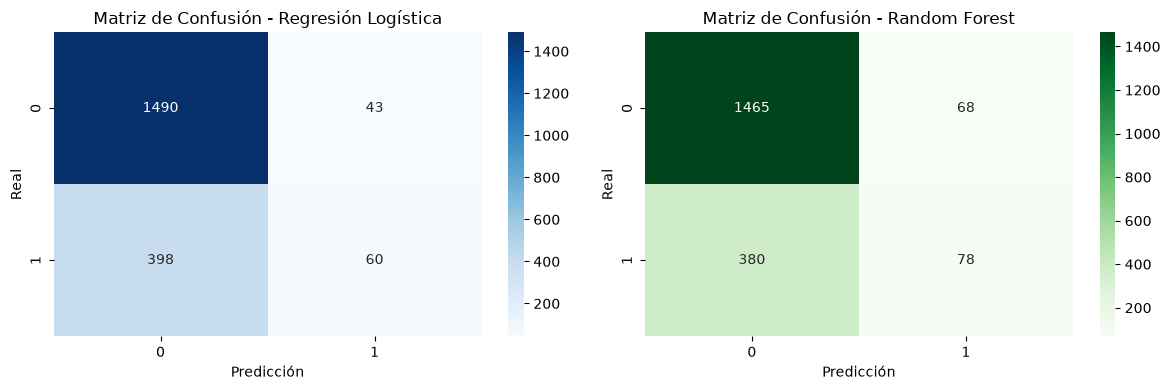

In [3]:
# 1. Reportes de Clasificación
print("=== REPORTE: REGRESIÓN LOGÍSTICA ===")
print(classification_report(y_test, y_pred_lr))

print("=== REPORTE: RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf))

# 2. Visualización de Matrices de Confusión (Corregido 'Greens')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Regresión Logística')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Random Forest')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# 1. Cargar el dataset procesado
df = pd.read_csv('../data/datacloud_churn_clean.csv')

# 2. Separar características (X) y variable objetivo (y)
X = df.drop(columns=['ID_Cliente', 'Churn'])
y = df['Churn']

# 3. División Stratified Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]} muestras")
print(f"Conjunto de Evaluación: {X_test.shape[0]} muestras")

# 4. Entrenamiento de Regresión Logística (Modelo Base)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 5. Entrenamiento de Random Forest (Modelo Ensamble)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("\n--- MODELADO COMPLETADO EXITOSAMENTE ---")

Conjunto de Entrenamiento: 7960 muestras
Conjunto de Evaluación: 1991 muestras

--- MODELADO COMPLETADO EXITOSAMENTE ---
